# Decision Tree — Bank Customer Retention

**University coursework | Artificial Intelligence — Faculty of Organizational Sciences, University of Belgrade**

This notebook applies a decision-tree classifier to a banking dataset to predict whether a customer **stayed** with the bank.

**Target convention:** `Stayed = 1` means the customer stayed, while `Stayed = 0` means the customer exited. Consequently, the default precision/recall/F1 values below refer to the **stayed** class, not to churn detection.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay,accuracy_score,precision_score,recall_score,f1_score
from sklearn.tree import DecisionTreeClassifier, plot_tree


## 1. Load and inspect the dataset

The original exercise provides a `bank.csv` file containing bank customer records.

In [2]:
df = pd.read_csv('bank.csv', na_values = ['-',' ', ''])
display(df.head())
print(df.info())


,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction.Score,Card.Type,Point.Earned
0,Hargrave,619,France,Female,NaN,2,0.00,1,1,1,101348.88,1,2,DIAMOND,464
1,Hill,608,Spain,Female,41.0,1,83807.86,1,0,1,112542.58,0,3,DIAMOND,456
2,Onio,502,France,Female,42.0,8,159660.80,3,1,0,113931.57,1,3,DIAMOND,377
3,Boni,699,France,Female,39.0,1,0.00,2,0,0,93826.63,0,5,GOLD,350
4,NaN,850,Spain,Female,43.0,2,125510.82,1,1,1,79084.10,0,5,GOLD,425


<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Surname             4897 non-null   str    
 1   CreditScore         4898 non-null   int64  
 2   Geography           4896 non-null   str    
 3   Gender              4898 non-null   str    
 4   Age                 4895 non-null   float64
 5   Tenure              4898 non-null   int64  
 6   Balance             4898 non-null   float64
 7   NumOfProducts       4898 non-null   int64  
 8   HasCrCard           4898 non-null   int64  
 9   IsActiveMember      4898 non-null   int64  
 10  EstimatedSalary     4898 non-null   float64
 11  Exited              4898 non-null   int64  
 12  Satisfaction.Score  4898 non-null   int64  
 13  Card.Type           4898 non-null   str    
 14  Point.Earned        4898 non-null   int64  
dtypes: float64(3), int64(8), str(4)
memory usage: 574.1 KB
None


## 2. Prepare the data

Drop text or categorical columns not used by this exercise. Encode `Gender` numerically and construct the `Stayed` target from `Exited`.

In [3]:
df = df.drop(columns=['Geography'])
df = df.drop(columns=['Surname'])
df = df.drop(columns=['Card.Type'])


In [4]:
df['Gender'] = df['Gender'].map({'Female':0, 'Male':1})


In [5]:
df['Stayed'] = np.where(df['Exited']==0,'Yes','No')
df['Stayed'] = df['Stayed'].map({'Yes':1, 'No':0})

df = df.drop(columns = ['Exited'])


In [6]:
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CreditScore         4898 non-null   int64  
 1   Gender              4898 non-null   int64  
 2   Age                 4895 non-null   float64
 3   Tenure              4898 non-null   int64  
 4   Balance             4898 non-null   float64
 5   NumOfProducts       4898 non-null   int64  
 6   HasCrCard           4898 non-null   int64  
 7   IsActiveMember      4898 non-null   int64  
 8   EstimatedSalary     4898 non-null   float64
 9   Satisfaction.Score  4898 non-null   int64  
 10  Point.Earned        4898 non-null   int64  
 11  Stayed              4898 non-null   int64  
dtypes: float64(3), int64(9)
memory usage: 459.3 KB
None


### Inspect missing values

In [7]:
print(df.isna().sum())


CreditScore           0
Gender                0
Age                   3
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Point.Earned          0
Stayed                0
dtype: int64


### Check the age distribution and fill missing ages

We use the median, following the original practice approach.

In [8]:
from scipy.stats import shapiro
p_age = shapiro(df['Age'].dropna())[1]
print(p_age)

df['Age'] = df['Age'].fillna(df['Age'].median())


3.8097649121487584e-39


### Create a subset

Keep rows with age at most 87, as in the exercise.

In [9]:
df_subset = df[df['Age']<=87].copy()


In [10]:
print(df_subset.isna().sum())


CreditScore           0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction.Score    0
Point.Earned          0
Stayed                0
dtype: int64


## 3. Explore predictors

Compare distributions for customers who stayed versus those who exited. In this exercise, selected columns are dropped after visual inspection. This selection is exploratory, not a formal feature-importance test.

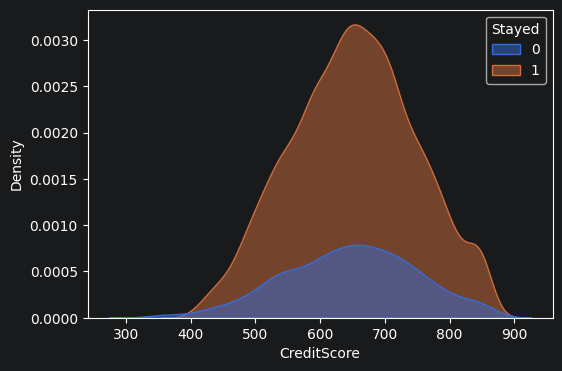

In [11]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='CreditScore',hue='Stayed',fill=True,alpha=0.5)
plt.show()

df_subset = df_subset.drop(columns=['CreditScore'])


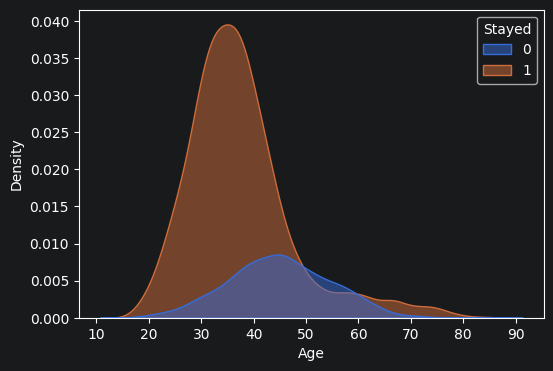

In [12]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='Age',hue='Stayed',fill=True,alpha=0.5)
plt.show()


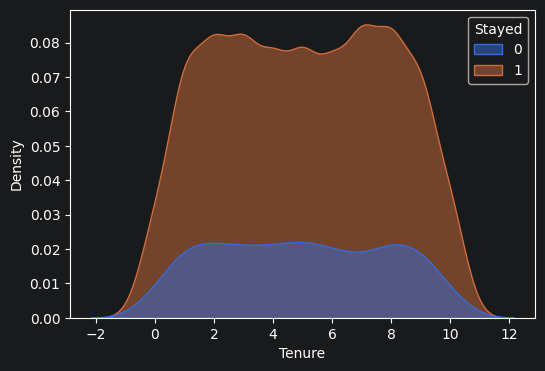

In [13]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='Tenure',hue='Stayed',fill=True,alpha=0.5)
plt.show()

df_subset = df_subset.drop(columns=['Tenure'])


### Compare balances and product counts

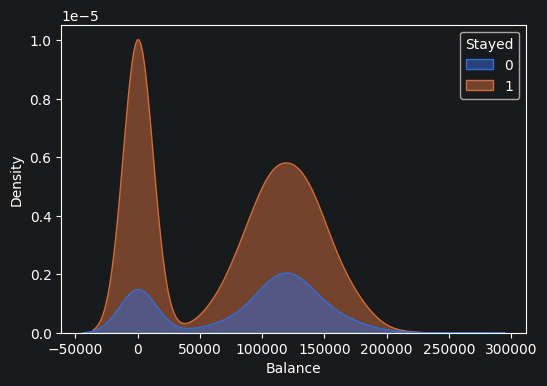

In [14]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='Balance',hue='Stayed',fill=True,alpha=0.5)
plt.show()


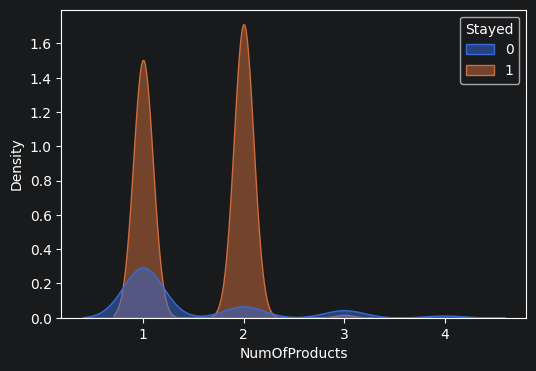

In [15]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='NumOfProducts',hue='Stayed',fill=True,alpha=0.5)
plt.show()


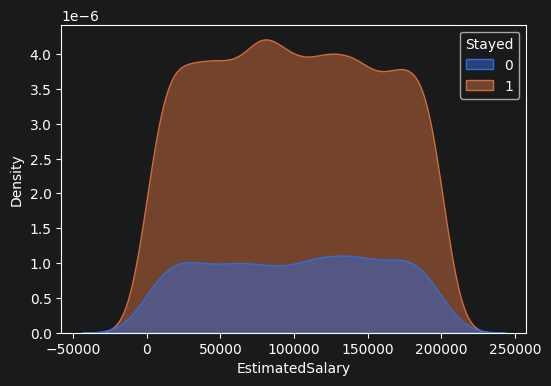

In [16]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='EstimatedSalary',hue='Stayed',fill=True,alpha=0.5)
plt.show()

df_subset = df_subset.drop(columns=['EstimatedSalary'])


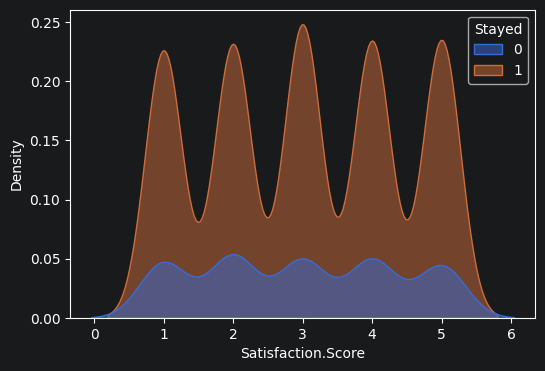

In [17]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='Satisfaction.Score',hue='Stayed',fill=True,alpha=0.5)
plt.show()

df_subset = df_subset.drop(columns=['Satisfaction.Score'])


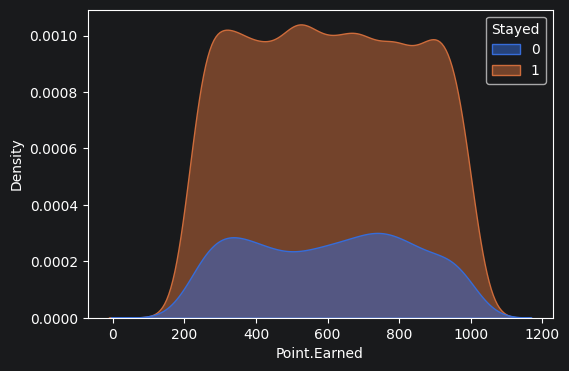

In [18]:
plt.figure(figsize=(6,4))
sb.kdeplot(data=df_subset,x='Point.Earned',hue='Stayed',fill=True,alpha=0.5)
plt.show()
df_subset = df_subset.drop(columns = ['Point.Earned'])


### Compare categorical and binary attributes

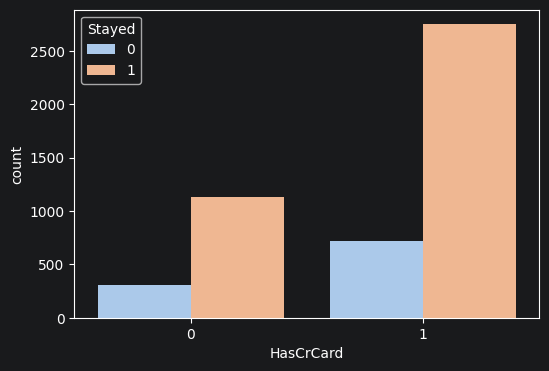

In [19]:
plt.figure(figsize=(6,4))
sb.countplot(data=df_subset,x='HasCrCard',hue='Stayed', palette='pastel')
plt.show()

df_subset = df_subset.drop(columns=['HasCrCard'])


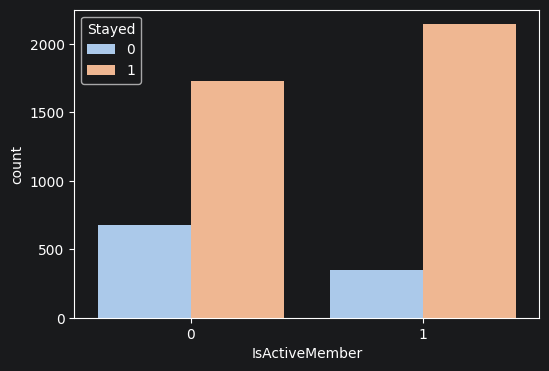

In [20]:
plt.figure(figsize=(6,4))
sb.countplot(data=df_subset,x='IsActiveMember',hue='Stayed', palette='pastel')
plt.show()


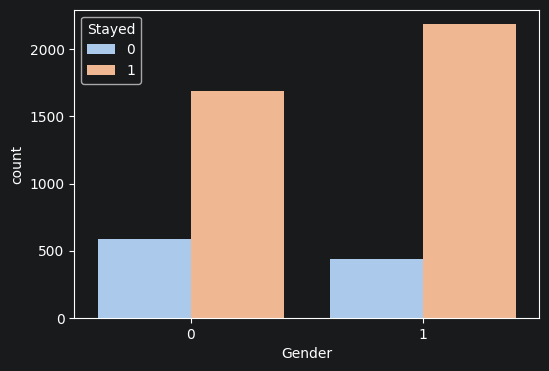

In [21]:
plt.figure(figsize=(6,4))
sb.countplot(data=df_subset,x='Gender',hue='Stayed', palette='pastel')
plt.show()


### Inspect the final feature table

In [22]:
print(df_subset.info())


<class 'pandas.DataFrame'>
Index: 4897 entries, 0 to 4897
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          4897 non-null   int64  
 1   Age             4897 non-null   float64
 2   Balance         4897 non-null   float64
 3   NumOfProducts   4897 non-null   int64  
 4   IsActiveMember  4897 non-null   int64  
 5   Stayed          4897 non-null   int64  
dtypes: float64(2), int64(4)
memory usage: 267.8 KB
None


## 4. Split into training and testing sets

A stratified 80/20 split keeps similar target-class proportions in both subsets.

In [23]:
y = df_subset['Stayed']
X = df_subset.drop(columns=['Stayed'])

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)


## 5. Find a pruning parameter

`GridSearchCV` and `StratifiedKFold` were used in the exercise to select `ccp_alpha`, the parameter controlling tree pruning. The search only uses the training subset.

In [24]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
param_grid = {'ccp_alpha': np.arange(0.00, 0.05, 0.0025)}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                    cv=cv,
                    param_grid=param_grid,
                    scoring='accuracy')

grid.fit(X_train,y_train)
best_ccp_alpha = grid.best_params_['ccp_alpha']
print(best_ccp_alpha)


0.0025


## 6. Train and visualize the decision tree

In [25]:
tree = DecisionTreeClassifier(random_state=42,ccp_alpha=best_ccp_alpha)
tree.fit(X_train,y_train)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

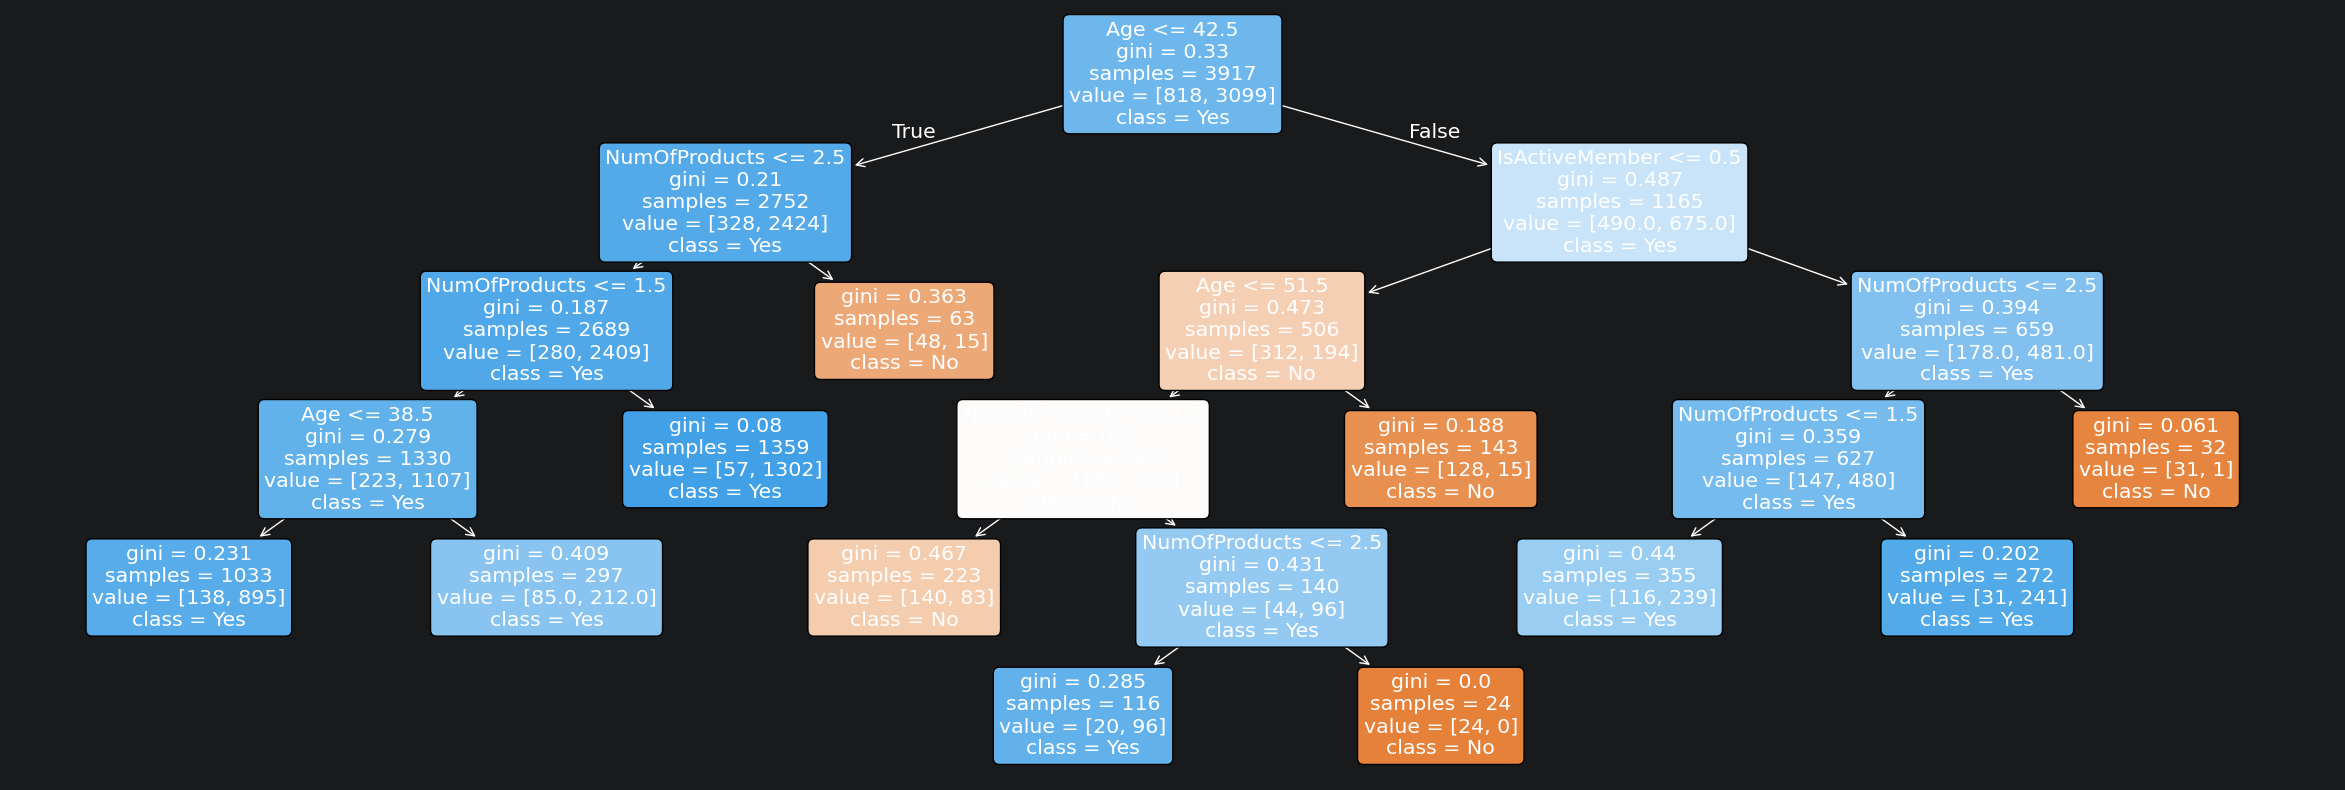

In [26]:
plt.figure(figsize=(30,10))
plot_tree(tree,
          feature_names=X_train.columns,
          class_names=['No','Yes'],
          filled=True,
          rounded=True)
plt.show()


## 7. Predict on the test set

In [27]:
y_pred = tree.predict(X_test)


### Confusion matrix

The class labels are `No` (0: customer exited) and `Yes` (1: customer stayed).

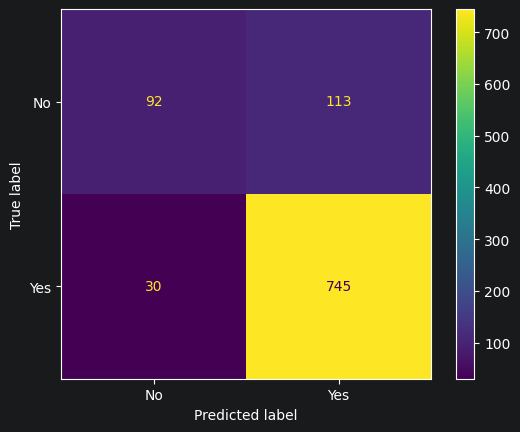

In [28]:
cm1 = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm1,display_labels=['No','Yes'])
disp.plot()
plt.show()


### Interpretation of the Confusion Matrix

The confusion matrix shows how successfully the model predicts whether customers will stay with the bank.

- True Positives (TP = 745): Customers who were correctly predicted to stay.
- True Negatives (TN = 92): Customers who were correctly predicted to leave.
- False Positives (FP = 113): Customers who actually left, but the model predicted they would stay.
- False Negatives (FN = 30): Customers who stayed, but the model predicted they would leave.

The model successfully identifies most customers who stay with the bank. However, it has more difficulty identifying customers who leave, as 113 of them were incorrectly classified as staying.

This is an important limitation if the model is intended to help the bank identify customers at risk of leaving.

### Calculate classification metrics

Accuracy measures overall correctness. Precision, recall and F1 here use `Stayed = 1` as the positive class.

In [29]:
def metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred,pos_label=1)
    recall = recall_score(y_true, y_pred,pos_label=1)
    f1 = f1_score(y_true, y_pred,pos_label=1)
    return{
        'accuracy':accuracy,
        'precision':precision,
        'recall':recall,
        'f1':f1
    }


### View the test results

In [30]:
tree_eval = metrics(y_test,y_pred)
print(tree_eval)


{'accuracy': 0.8540816326530613, 'precision': 0.8682983682983683, 'recall': 0.9612903225806452, 'f1': 0.9124311083894673}


### Interpretation of Model Performance

**Accuracy (85.41%)**

The model correctly classified approximately 85.4% of customers in the test dataset, regardless of whether they stayed or left the bank.

**Precision (86.83%)**

Of all customers predicted to stay with the bank, approximately 86.8% actually stayed.

**Recall (96.13%)**

Of all customers who actually stayed with the bank, the model correctly identified approximately 96.1%.

**F1-Score (91.24%)**

The F1-score combines precision and recall into a single metric. The result indicates relatively strong performance when identifying customers who stay.

**Overall Assessment**

Although the model achieves relatively high accuracy, precision, recall, and F1-score for the positive class (Stayed = 1), its performance is weaker when identifying customers who leave.

Only 92 out of 205 customers who left were correctly identified, corresponding to approximately 44.9% recall for the exited class.

Therefore, while the model performs well at predicting customer retention, additional improvements would be necessary if the primary business objective were identifying customers likely to leave.

## 8. Conclusions and limitations

- A decision tree can be trained and tested on a bank customer retention dataset using `scikit-learn`.
- The confusion matrix and class-specific precision, recall and F1 should be interpreted together with accuracy, particularly when classes are imbalanced.
- The default positive class in this notebook is **customers who stayed**. If the business goal were identifying customers likely to leave, the evaluation would need to focus on the **exited** class instead.
- As in the original university exercise, some exploratory feature selection and age imputation occur before train/test splitting. A more rigorous project would base those choices on training data only.
- These are academic exercise results, not a validated bank churn product or business recommendation.